# Developing a Machine Learning Application for Prediction of Rainfall in Lusaka Province
**Faith Lubinda (2018216236) — University of Zambia, B.Eng. Electrical & Electronic Engineering**

## Step 0 — Install libraries 

In [1]:
!pip install pandas numpy scikit-learn xgboost matplotlib seaborn

## Step 1 — Import libraries 

In [2]:
import tkinter as tk
from tkinter import messagebox
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
plt.style.use('Solarize_Light2')

## Step 1b — Locate the data files


In [3]:
import os, re
from pathlib import Path

DATA_FOLDER = None     # e.g. r"C:\Users\YourName\Desktop\rainfall"

def _simplify(name):
    # 'Rufunsa Daily Data (1).xlsx' -> 'rufunsadailydata1'
    return re.sub(r'[^a-z0-9]', '', Path(name).stem.lower())

def find_file(file_name):
    if DATA_FOLDER:
        folders = [Path(DATA_FOLDER)]
    else:
        home = Path.home()
        folders = [Path.cwd(), home / 'Desktop', home / 'Downloads', home / 'Documents',
                   home / 'OneDrive', home / 'OneDrive' / 'Desktop', home / 'OneDrive' / 'Documents']
    target, ext = _simplify(file_name), Path(file_name).suffix.lower()
    close_matches = []
    for folder in folders:
        if not folder.exists():
            continue
        exact = folder / file_name
        if exact.exists():
            return str(exact)
        for path in folder.rglob('*' + ext):
            name = _simplify(path.name)
            if name == target:
                return str(path)
            if name.startswith(target) or target in name:
                close_matches.append(path)
    if close_matches:
        return str(close_matches[0])
    raise FileNotFoundError(
        f"Could not find '{file_name}'. Put it in the same folder as this notebook "
        f"({Path.cwd()}) or set DATA_FOLDER above to the folder that holds it.")

FIGURE_FOLDER = Path.cwd() / "figures"
FIGURE_FOLDER.mkdir(exist_ok=True)

def save_and_show(name):
    # Saves the current chart as a PNG (for your report) and shows it in the notebook
    plt.savefig(FIGURE_FOLDER / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

print("Notebook folder:", Path.cwd())
print("Charts will also be saved in:", FIGURE_FOLDER)

Notebook folder: C:\Users\FAITH\Downloads
Charts will also be saved in: C:\Users\FAITH\Downloads\figures


## Step 2 — Read the data from the CSV file

In [4]:
DATA_FILE = find_file("RAINFALL LUSAKA.csv")
print("Using:", DATA_FILE)
data = pd.read_csv(DATA_FILE)
data.head()

Using: C:\Users\FAITH\Downloads\RAINFALL LUSAKA.csv


,Station_Name,rainFall,maxTemp,minTemp,windSpeed,humidity,pressure,rainFallToday,rainFallTomorrow
0,LUSAKA CITY AIRPOR,569.6,28.5,9.7,10,56,874.4,YES,NO
1,LUSAKA CITY AIRPOR,180.9,25.5,6.5,10,75,873.9,YES,NO
2,LUSAKA CITY AIRPOR,409.6,25.0,7.4,10,81,875.8,YES,NO
3,LUSAKA CITY AIRPOR,252.1,29.0,6.4,10,71,877.2,YES,NO
4,LUSAKA CITY AIRPOR,4.0,33.0,9.0,10,62,878.0,YES,NO


## Step 3 — Summary statistics 

In [5]:
data.describe()

,rainFall,maxTemp,minTemp,windSpeed,humidity,pressure
count,339.000000,339.000000,339.000000,339.000000,339.000000,339.000000
mean,78.217404,30.261947,11.505900,8.643068,58.707965,876.639823
std,115.753769,6.390317,3.434462,1.669258,14.100242,4.358645
min,0.000000,0.000000,3.900000,0.000000,4.000000,871.200000
25%,0.000000,29.000000,8.500000,8.000000,50.500000,874.400000
50%,24.400000,30.400000,11.500000,9.000000,60.000000,875.500000
75%,121.750000,33.600000,14.000000,10.000000,70.000000,878.000000
max,569.600000,39.500000,20.600000,10.000000,88.000000,917.600000


## Step 4 — Dimensions of the DataFrame 

In [6]:
data.shape

(339, 9)

## Step 5 — DataFrame information 

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 339 entries, 0 to 338
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Station_Name      339 non-null    str    
 1   rainFall          339 non-null    float64
 2   maxTemp           339 non-null    float64
 3   minTemp           339 non-null    float64
 4   windSpeed         339 non-null    int64  
 5   humidity          339 non-null    int64  
 6   pressure          339 non-null    float64
 7   rainFallToday     339 non-null    str    
 8   rainFallTomorrow  339 non-null    str    
dtypes: float64(4), int64(2), str(3)
memory usage: 31.6 KB


## Step 6 — Remove rows with missing values 

In [8]:
data = data.dropna(axis=0)
data.shape

(339, 9)

## Step 7 — Column names 

In [9]:
data.columns

Index(['Station_Name', 'rainFall', 'maxTemp', 'minTemp', 'windSpeed',
       'humidity', 'pressure', 'rainFallToday', 'rainFallTomorrow'],
      dtype='str')

## Step 8 — Encode values with LabelEncoder 
Done on a **copy** (`data_encoded`) so the real values in `data` stay intact for model training below.

In [10]:
data_encoded = data.copy()
le = LabelEncoder()
data_encoded['windSpeed'] = le.fit_transform(data_encoded['windSpeed'])
data_encoded['pressure'] = le.fit_transform(data_encoded['pressure'])
data_encoded['humidity'] = le.fit_transform(data_encoded['humidity'])
data_encoded['rainFall'] = le.fit_transform(data_encoded['rainFall'])
data_encoded['maxTemp'] = le.fit_transform(data_encoded['maxTemp'])
data_encoded['minTemp'] = le.fit_transform(data_encoded['minTemp'])

## Step 9 — First few rows after encoding 

In [11]:
data_encoded.head()

,Station_Name,rainFall,maxTemp,minTemp,windSpeed,humidity,pressure,rainFallToday,rainFallTomorrow
0,LUSAKA CITY AIRPOR,80,15,25,7,20,15,YES,NO
1,LUSAKA CITY AIRPOR,62,2,4,7,38,10,YES,NO
2,LUSAKA CITY AIRPOR,78,1,8,7,43,27,YES,NO
3,LUSAKA CITY AIRPOR,69,18,3,7,34,37,YES,NO
4,LUSAKA CITY AIRPOR,2,46,20,7,26,44,YES,NO


## Step 10 — Separate features (x) and target (y)

In [12]:
x = data_encoded.drop(['rainFall'], axis=1)
y = data_encoded['rainFall']
x.head()

,Station_Name,maxTemp,minTemp,windSpeed,humidity,pressure,rainFallToday,rainFallTomorrow
0,LUSAKA CITY AIRPOR,15,25,7,20,15,YES,NO
1,LUSAKA CITY AIRPOR,2,4,7,38,10,YES,NO
2,LUSAKA CITY AIRPOR,1,8,7,43,27,YES,NO
3,LUSAKA CITY AIRPOR,18,3,7,34,37,YES,NO
4,LUSAKA CITY AIRPOR,46,20,7,26,44,YES,NO


## Step 11 — Scatterplot of temperature variables and rainfall 

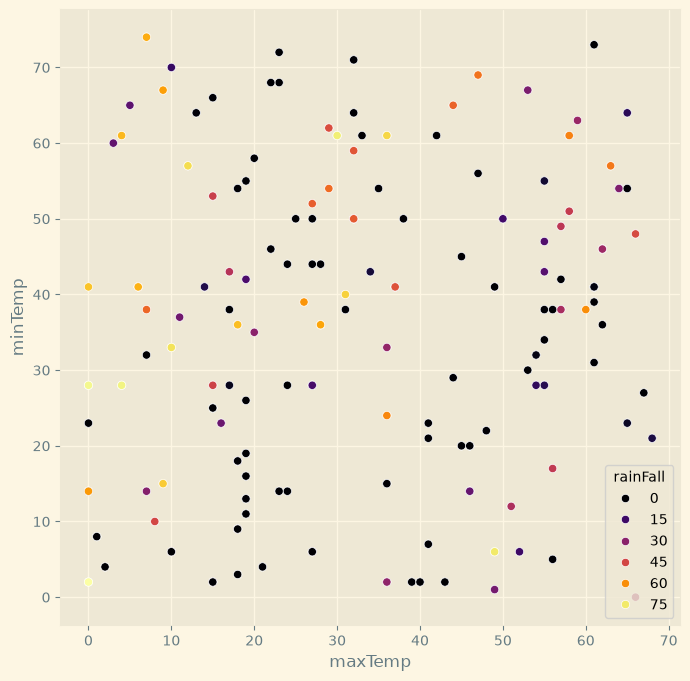

In [13]:
plt.figure(figsize=(8, 8))
sns.scatterplot(x='maxTemp', y='minTemp', hue='rainFall', palette='inferno', data=data_encoded)
save_and_show("fig_3_20_temperature_vs_rainfall")

## Step 12 — Prepare features and map rainfall into categories 
Zambia Meteorological Department: 1–25 mm light, 25–50 mm moderate, above 50 mm high.

In [14]:
data = pd.read_csv(DATA_FILE)

# Handle Missing Values in the target variable
data.dropna(subset=['rainFall'], inplace=True)

# Feature Engineering
features = ['maxTemp', 'minTemp', 'windSpeed', 'humidity', 'pressure']
X = data[features]
y = data['rainFall']

# Fill missing values in the features
imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(X)

# Map rainfall levels to categories
def map_rainfall_level(rainfall):
    if rainfall == 0:
        return "No Rainfall"
    elif rainfall <= 25:
        return "Light Rainfall"
    elif rainfall <= 50:
        return "Moderate Rainfall"
    else:
        return "High Rainfall"

y = y.apply(map_rainfall_level)
y.value_counts()

rainFall
High Rainfall        149
No Rainfall          146
Light Rainfall        24
Moderate Rainfall     20
Name: count, dtype: int64

In [15]:
# Encode target variable as numeric values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split the data into training and testing sets (random_state makes results repeatable)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model Training
log_reg_model = LogisticRegression(max_iter=5000)
log_reg_model.fit(X_train, y_train)

svc_model = SVC()
svc_model.fit(X_train, y_train)

xgb_model = GradientBoostingClassifier()
xgb_model.fit(X_train, y_train)

# Calculate Model Accuracy
accuracy_log_reg = accuracy_score(y_test, log_reg_model.predict(X_test))
accuracy_svc = accuracy_score(y_test, svc_model.predict(X_test))
accuracy_xgb = accuracy_score(y_test, xgb_model.predict(X_test))

print(f"Logistic Regression Accuracy: {accuracy_log_reg:.2f}")
print(f"SVC Accuracy: {accuracy_svc:.2f}")
print(f"XGBoost Accuracy: {accuracy_xgb:.2f}")

Logistic Regression Accuracy: 0.43
SVC Accuracy: 0.38
XGBoost Accuracy: 0.57


## Step 14 — Quick test prediction without the GUI
Uses the same values as Fig 3.27.

In [16]:
def verbal_rainfall_prediction(value):
    # Turns the model's number back into its category name
    return label_encoder.inverse_transform([value])[0]

sample = np.array([[34, 17, 4, 45, 871.5]])   # maxTemp, minTemp, windSpeed, humidity, pressure
print("Logistic Regression:", verbal_rainfall_prediction(log_reg_model.predict(sample)[0]))
print("SVC:", verbal_rainfall_prediction(svc_model.predict(sample)[0]))
print("XGBoost:", verbal_rainfall_prediction(xgb_model.predict(sample)[0]))

Logistic Regression: No Rainfall
SVC: No Rainfall
XGBoost: Moderate Rainfall


## Part B — Time series analysis and seasonal XGBoost (Fig 3.21, 3.22, 3.28)
Two dated data sources are used here. The files are found automatically by `find_file` (Step 1b):

| File | What it holds |
|---|---|
| `Rufunsa_Daily_Data.xlsx` | Daily automatic weather station data for Rufunsa (Lusaka Province), May 2021 – July 2023, **including rainfall** |
| `max_temp.csv`, `min_temp.csv`, `humidity.csv`, `windspeed.csv`, `pressure.csv` | Monthly averages, 1980 – 2023, for Lusaka City Airport, Lusaka Int. Airport and Mt. Makulu |

### B1 — Load and clean the Rufunsa daily data
* The station logs each day's totals at midnight, so the time stamp `2021-05-05 00:00` holds the readings for **4 May**. One day is subtracted to get the correct date.
* Wind speed is converted from m/s to km/h (× 3.6) so it matches the GUI.
* Daily humidity is taken as the average of the day's minimum and maximum relative humidity.

In [17]:
DAILY_FILE = find_file("Rufunsa_Daily_Data.xlsx")
print("Using:", DAILY_FILE)

raw = pd.read_excel(DAILY_FILE, header=1)          # row 0 is the sheet title
raw['Time Stamp'] = pd.to_datetime(raw['Time Stamp'], errors='coerce')
raw = raw.dropna(subset=['Time Stamp'])

data1 = pd.DataFrame({
    'Date':      raw['Time Stamp'] - pd.Timedelta(days=1),
    'Rainfall':  raw['Rain Tot'],
    'Maxtemp':   raw['Air Temp Max'],
    'Mintemp':   raw['Air Temp Min'],
    'Windspeed': raw['Wind Spd Avg'] * 3.6,                  # m/s -> km/h
    'Humidity':  (raw['RH Min'] + raw['RH Max']) / 2,
    'Pressure':  raw['BPress Avg'],
}).dropna().sort_values('Date').reset_index(drop=True)

print(data1.shape)
print("From", data1['Date'].min().date(), "to", data1['Date'].max().date())
data1.head()

Using: C:\Users\FAITH\Downloads\Rufunsa (Daily Data).xlsx
(796, 7)
From 2021-05-04 to 2023-07-10


,Date,Rainfall,Maxtemp,Mintemp,Windspeed,Humidity,Pressure
0,2021-05-04,0.8,29.76,17.35,6.950138,58.235,969.5596
1,2021-05-05,0.0,30.38,14.21,7.618057,61.470,970.0544
2,2021-05-06,0.0,31.94,12.95,7.664231,59.115,970.7643
3,2021-05-07,0.0,29.84,13.33,8.393288,60.900,972.2009
4,2021-05-08,0.0,29.44,13.05,7.949401,64.460,971.1596


In [18]:
data1.describe()

,Date,Rainfall,Maxtemp,Mintemp,Windspeed,Humidity,Pressure
count,796,796.000000,796.000000,796.000000,796.000000,796.000000,796.000000
mean,2022-06-05 22:22:18.693467,0.994975,33.112073,18.546275,7.777821,57.410099,968.518559
min,2021-05-04 00:00:00,0.000000,19.110000,7.595000,3.695530,21.610000,959.412700
25%,2021-11-18 18:00:00,0.000000,30.227500,14.300000,6.419288,48.103750,965.152275
50%,2022-06-05 12:00:00,0.000000,32.885000,19.900000,7.619278,58.065000,968.044750
75%,2022-12-21 06:00:00,0.000000,35.350000,22.322500,8.723187,68.062500,971.673750
max,2023-07-10 00:00:00,58.200000,44.660000,29.520000,19.313489,91.000000,980.315700
std,NaN,5.269117,3.940118,4.836504,1.960596,13.705319,4.172124


### B2 — Daily rainfall trend (Fig 3.21)

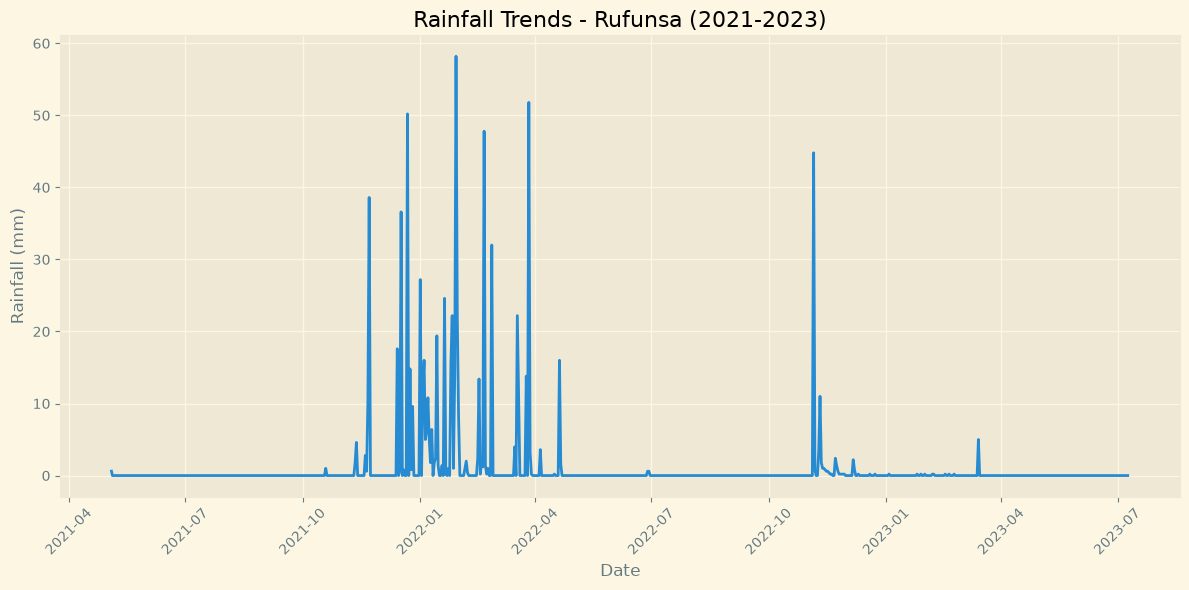

In [19]:
start_date = data1['Date'].min()
end_date = data1['Date'].max()
filtered_data = data1[(data1['Date'] >= start_date) & (data1['Date'] <= end_date)]

plt.figure(figsize=(12, 6))
plt.plot(filtered_data['Date'], filtered_data['Rainfall'], marker='', linestyle='-')
plt.title('Rainfall Trends - Rufunsa (2021-2023)')
plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')
plt.xticks(rotation=45)
plt.tight_layout()
save_and_show("fig_3_21_daily_rainfall_trend")

### B3 — Monthly rainfall totals
Shows clearly which months are wet (November – April) and which are dry (May – October).

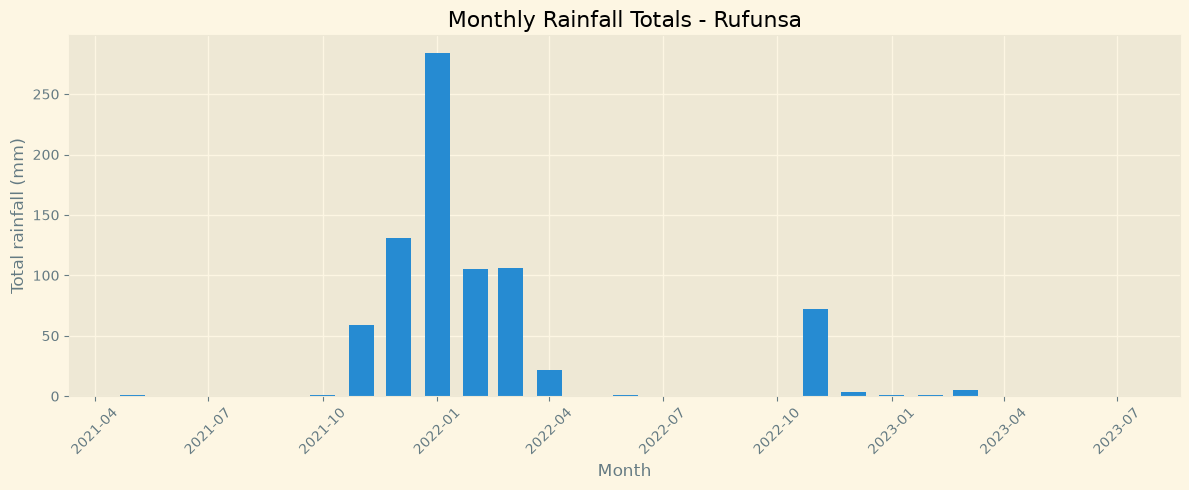

,Total rainfall (mm)
Date,
2021-05-01,0.8
2021-06-01,0.0
2021-07-01,0.0
2021-08-01,0.0
2021-09-01,0.0
2021-10-01,1.0
2021-11-01,58.8
2021-12-01,131.0
2022-01-01,284.4


In [20]:
monthly_rain = data1.set_index('Date')['Rainfall'].resample('MS').sum()

plt.figure(figsize=(12, 5))
plt.bar(monthly_rain.index, monthly_rain.values, width=20)
plt.title('Monthly Rainfall Totals - Rufunsa')
plt.xlabel('Month')
plt.ylabel('Total rainfall (mm)')
plt.xticks(rotation=45)
plt.tight_layout()
save_and_show("monthly_rainfall_totals")

monthly_rain.to_frame('Total rainfall (mm)')

### B4 — Remove the suspected rain-gauge fault
From December 2022 to March 2023 the gauge records almost no rain (under 6 mm a month) in the middle of the rainy season, while the other sensors keep working. That pattern looks like a blocked or faulty gauge, not a real drought. Leaving it in would teach the model that rainy-season weather brings no rain, so those months are removed. Set `EXCLUDE_GAUGE_FAULT = False` to keep them.

In [21]:
EXCLUDE_GAUGE_FAULT = True

if EXCLUDE_GAUGE_FAULT:
    fault = (data1['Date'] >= '2022-12-01') & (data1['Date'] <= '2023-03-31')
    data1 = data1[~fault].reset_index(drop=True)

print("Rows used for modelling:", len(data1))

Rows used for modelling: 677


### B5 — Long-term monthly climate series, 1980 – 2023
The monthly station files are in a wide layout (one row per station and year, one column per month). They are reshaped into one row per station and month, joined together, and obviously wrong pressure readings (above 900 hPa, which is impossible at Lusaka's altitude) are removed as outliers.

In [22]:
def load_monthly(file_name, value_name):
    path = find_file(file_name)
    print('Using:', path)
    df = pd.read_csv(path)
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]        # drop empty trailing columns
    df = df.dropna(subset=['Station_Name', 'YY'])
    long = df.melt(id_vars=['Station_Name', 'YY'], var_name='Month', value_name=value_name)
    long['Month'] = long['Month'].astype(int)
    long['Date'] = pd.to_datetime(dict(year=long['YY'].astype(int), month=long['Month'], day=1))
    return long[['Station_Name', 'Date', value_name]]

monthly = load_monthly('max_temp.csv', 'Maxtemp')
for file_name, name in [('min_temp.csv', 'Mintemp'), ('humidity.csv', 'Humidity'),
                        ('windspeed.csv', 'Windspeed'), ('pressure.csv', 'Pressure')]:
    monthly = monthly.merge(load_monthly(file_name, name), on=['Station_Name', 'Date'], how='outer')

monthly.loc[monthly['Pressure'] > 900, 'Pressure'] = np.nan     # outlier removal
monthly.loc[monthly['Windspeed'] == 0, 'Windspeed'] = np.nan    # 0.0 monthly mean is a recording error
monthly = monthly.sort_values(['Station_Name', 'Date']).reset_index(drop=True)

print(monthly.shape)
monthly.groupby('Station_Name').count()

Using: C:\Users\FAITH\Downloads\max temp.csv
Using: C:\Users\FAITH\Downloads\min temp.csv
Using: C:\Users\FAITH\Downloads\humidity.csv
Using: C:\Users\FAITH\Downloads\windspeed.csv
Using: C:\Users\FAITH\Downloads\pressure.csv
(1536, 7)


,Date,Maxtemp,Mintemp,Humidity,Windspeed,Pressure
Station_Name,,,,,,
LUSAKA CITY AIRPOR,528,324,279,110,103,128
LUSAKA INT. AIRPOR,528,368,251,365,23,367
MT. MAKULU AGROME,480,412,343,17,201,45


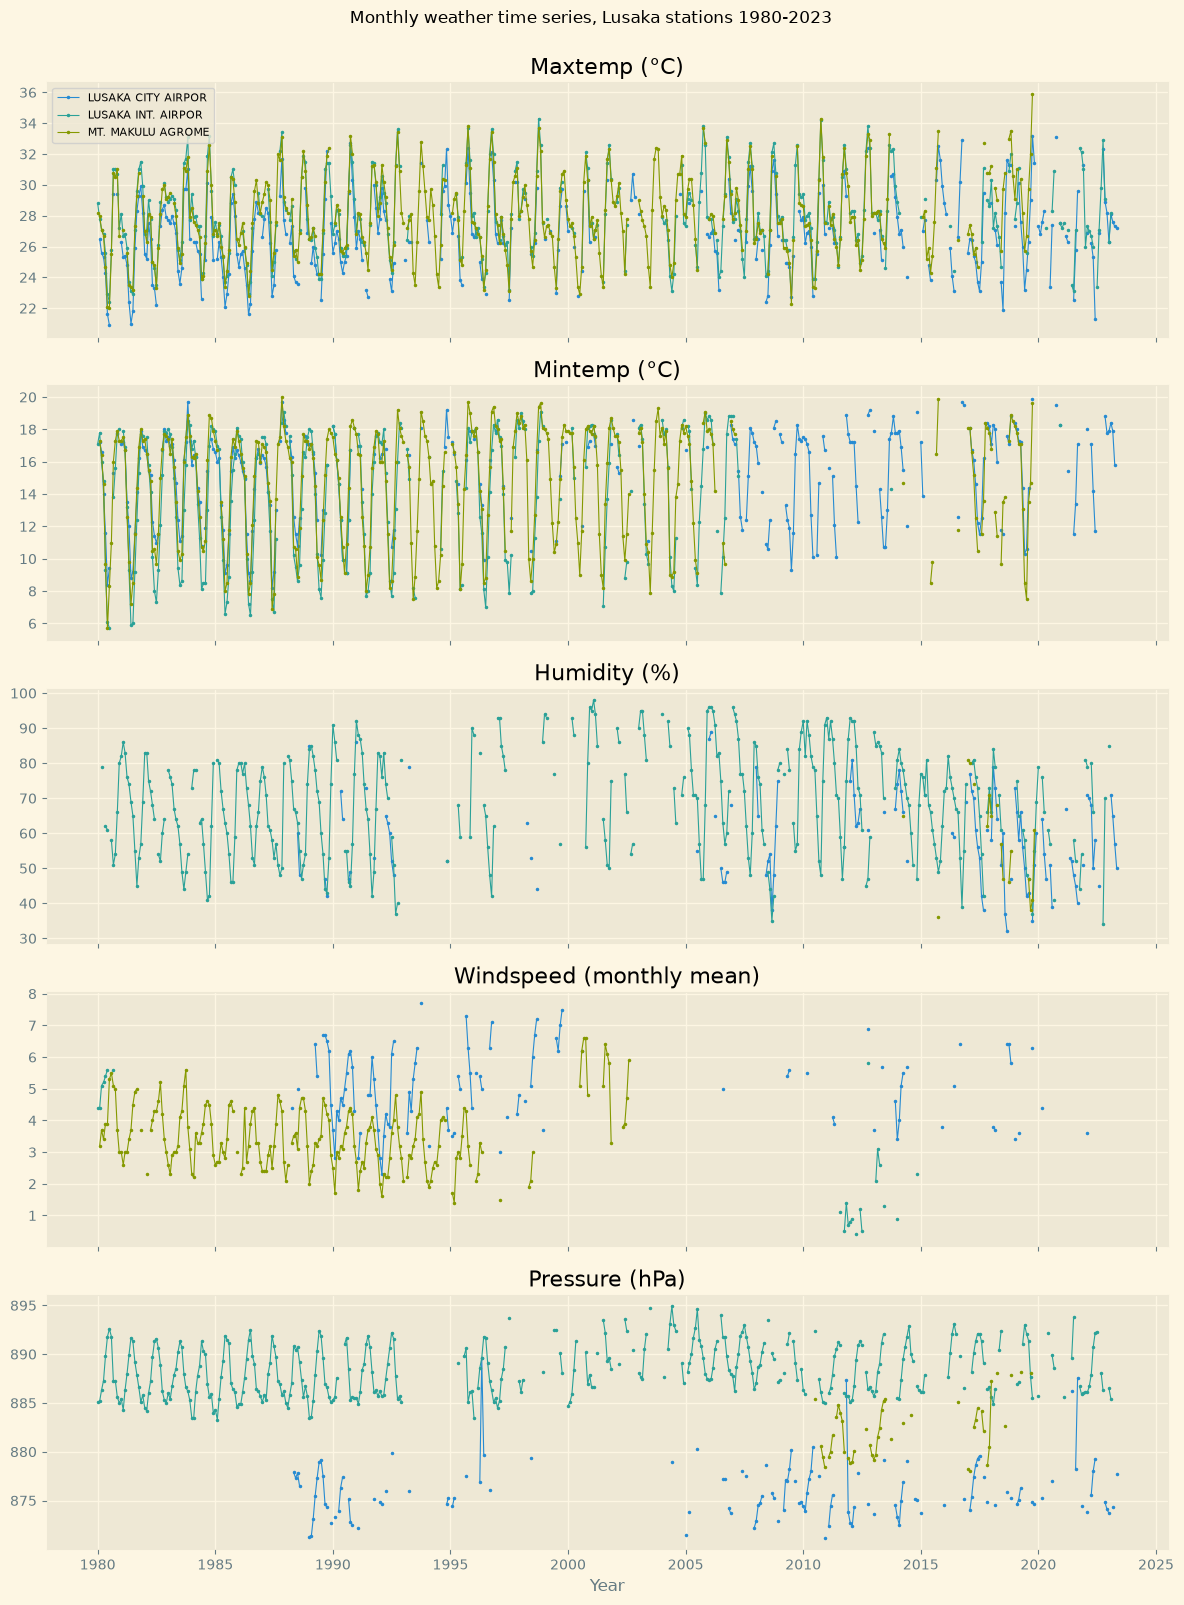

In [23]:
variables = ['Maxtemp', 'Mintemp', 'Humidity', 'Windspeed', 'Pressure']
units = ['°C', '°C', '%', 'monthly mean', 'hPa']

fig, axes = plt.subplots(len(variables), 1, figsize=(12, 16), sharex=True)
for ax, var, unit in zip(axes, variables, units):
    for station, group in monthly.groupby('Station_Name'):
        # put every month in, so missing months appear as gaps instead of straight joining lines
        g = group.set_index('Date')[var].asfreq('MS')
        ax.plot(g.index, g.values, marker='.', linestyle='-', linewidth=0.8, markersize=3, label=station)
    ax.set_title(f'{var} ({unit})')
axes[0].legend(loc='upper left', fontsize=8)
axes[-1].set_xlabel('Year')
plt.suptitle('Monthly weather time series, Lusaka stations 1980-2023', y=1.0)
plt.tight_layout()
save_and_show("monthly_weather_1980_2023")

### B6 — Average year (seasonal cycle) at each station
The hot, humid months (October – March) line up with the rainy season seen in B3.

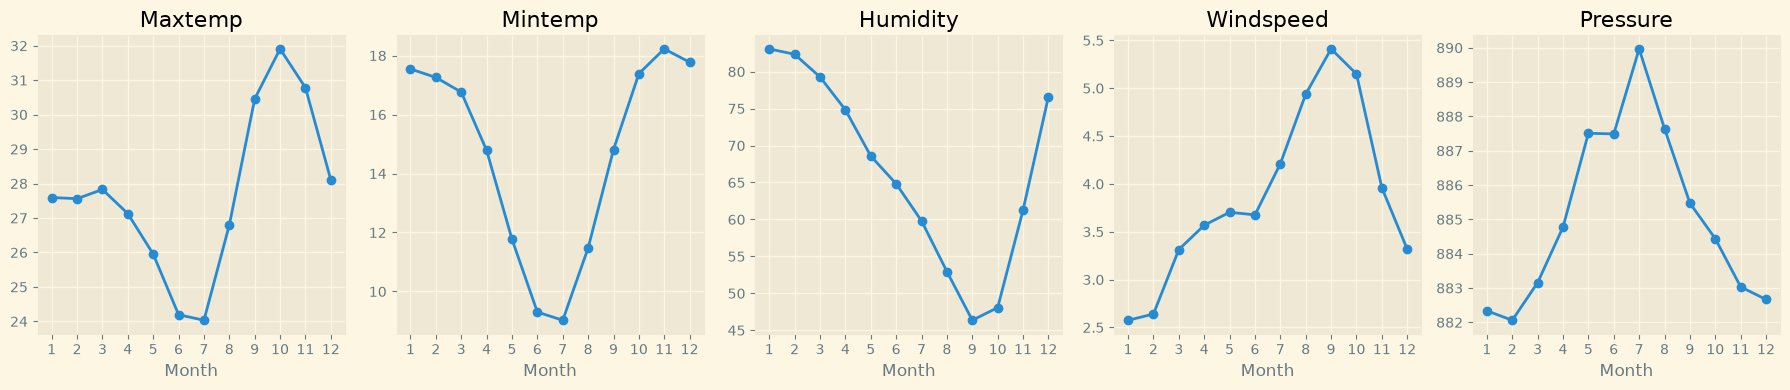

,Maxtemp,Mintemp,Humidity,Windspeed,Pressure
MonthNo,,,,,
1,27.6,17.5,83.1,2.6,882.3
2,27.6,17.3,82.3,2.6,882.1
3,27.8,16.8,79.3,3.3,883.2
4,27.1,14.8,74.8,3.6,884.8
5,26.0,11.8,68.6,3.7,887.5
6,24.2,9.3,64.8,3.7,887.5
7,24.0,9.0,59.8,4.2,890.0
8,26.8,11.5,53.0,4.9,887.6
9,30.5,14.8,46.4,5.4,885.5


In [24]:
monthly['MonthNo'] = monthly['Date'].dt.month
climatology = monthly.groupby('MonthNo')[variables].mean()

fig, axes = plt.subplots(1, len(variables), figsize=(18, 4))
for ax, var in zip(axes, variables):
    ax.plot(climatology.index, climatology[var], marker='o')
    ax.set_title(var)
    ax.set_xticks(range(1, 13))
    ax.set_xlabel('Month')
plt.tight_layout()
save_and_show("average_year_seasonal_cycle")

climatology.round(1)

### B7 — Train one XGBoost model per season (Fig 3.22)
Season 1 = rainy season (October – April), Season 2 = dry season (May – September). 20 % of each season is held back to test the model.

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

season1_data = data1[(data1["Date"].dt.month >= 10) | (data1["Date"].dt.month <= 4)]
season2_data = data1[(data1["Date"].dt.month >= 5) & (data1["Date"].dt.month <= 9)]

ts_features = ['Maxtemp', 'Mintemp', 'Windspeed', 'Humidity', 'Pressure']

X_season1 = season1_data[ts_features]
y_season1 = season1_data['Rainfall']
X_season2 = season2_data[ts_features]
y_season2 = season2_data['Rainfall']

X1_train, X1_test, y1_train, y1_test = train_test_split(X_season1, y_season1, test_size=0.2, random_state=42)
X2_train, X2_test, y2_train, y2_test = train_test_split(X_season2, y_season2, test_size=0.2, random_state=42)

xgb_model_season1 = xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
xgb_model_season1.fit(X1_train, y1_train)

xgb_model_season2 = xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
xgb_model_season2.fit(X2_train, y2_train)

for name, model, Xt, yt in [('Rainy season (Oct-Apr)', xgb_model_season1, X1_test, y1_test),
                            ('Dry season (May-Sep)', xgb_model_season2, X2_test, y2_test)]:
    pred = np.clip(model.predict(Xt), 0, None)
    print(f"{name}:  MAE = {mean_absolute_error(yt, pred):.2f} mm   "
          f"RMSE = {np.sqrt(mean_squared_error(yt, pred)):.2f} mm   (test days: {len(yt)})")

Rainy season (Oct-Apr):  MAE = 3.45 mm   RMSE = 7.48 mm   (test days: 61)
Dry season (May-Sep):  MAE = 0.02 mm   RMSE = 0.12 mm   (test days: 75)


### B8 — Actual vs predicted rainfall on the rainy-season test days

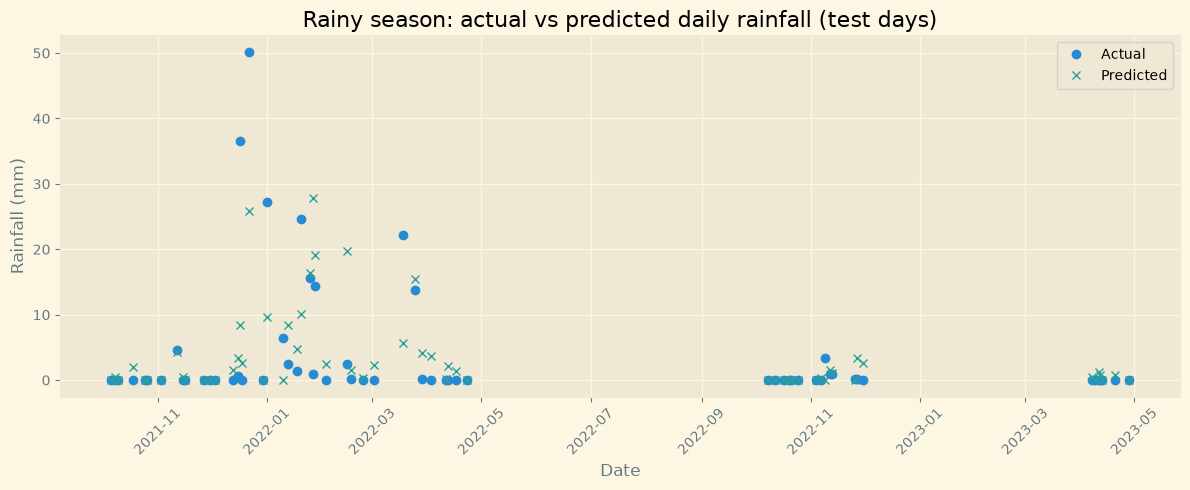

In [26]:
compare = season1_data.loc[X1_test.index, ['Date', 'Rainfall']].copy()
compare['Predicted'] = np.clip(xgb_model_season1.predict(X1_test), 0, None)
compare = compare.sort_values('Date')

plt.figure(figsize=(12, 5))
plt.plot(compare['Date'], compare['Rainfall'], marker='o', linestyle='', label='Actual')
plt.plot(compare['Date'], compare['Predicted'], marker='x', linestyle='', label='Predicted')
plt.title('Rainy season: actual vs predicted daily rainfall (test days)')
plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
save_and_show("actual_vs_predicted_rainfall")

### B9 — Feature importance (which weather variable matters most)

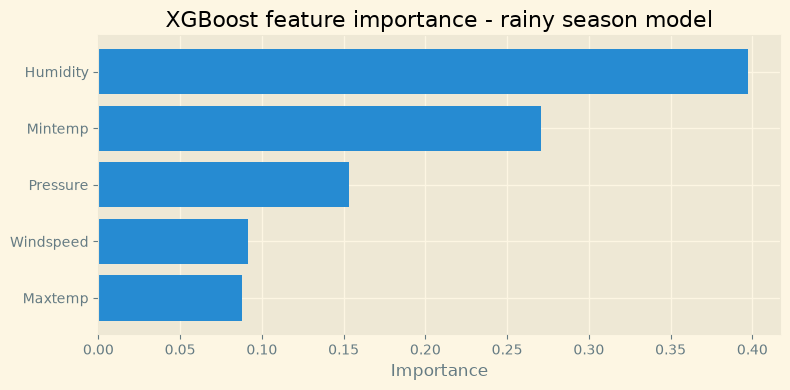

In [27]:
importance = pd.Series(xgb_model_season1.feature_importances_, index=ts_features).sort_values()

plt.figure(figsize=(8, 4))
plt.barh(importance.index, importance.values)
plt.title('XGBoost feature importance - rainy season model')
plt.xlabel('Importance')
plt.tight_layout()
save_and_show("feature_importance")

## Part C — Prediction windows (GUIs)
These open in a **separate window**, which can appear *behind* your browser — check the taskbar. The cell shows `[*]` until you close the window. All charts above are already done by the time you get here.

Run Part A and Part B first: the first window uses the Part A models, the second uses the seasonal models from Part B.

### C1 — Rainfall Prediction GUI (Fig 3.25 – 3.27)
A window opens. The cell keeps running (shows `[*]`) until you close the window — close it before running the next cell.

In [28]:
# Create the GUI
root = tk.Tk()
root.title("Rainfall Prediction")

# Labels
tk.Label(root, text="Enter Today's Weather Conditions", font=("Helvetica", 14, "bold")).grid(row=0, columnspan=2, pady=10)

# Entry Fields
max_temp_entry = tk.Entry(root)
min_temp_entry = tk.Entry(root)
wind_speed_entry = tk.Entry(root)
humidity_entry = tk.Entry(root)
pressure_entry = tk.Entry(root)

tk.Label(root, text="Max Temperature (°C):").grid(row=1, column=0, padx=5, pady=5)
tk.Label(root, text="Min Temperature (°C):").grid(row=2, column=0, padx=5, pady=5)
tk.Label(root, text="Wind Speed (km/h):").grid(row=3, column=0, padx=5, pady=5)
tk.Label(root, text="Humidity (%):").grid(row=4, column=0, padx=5, pady=5)
tk.Label(root, text="Pressure (hPa):").grid(row=5, column=0, padx=5, pady=5)

max_temp_entry.grid(row=1, column=1, padx=5, pady=5)
min_temp_entry.grid(row=2, column=1, padx=5, pady=5)
wind_speed_entry.grid(row=3, column=1, padx=5, pady=5)
humidity_entry.grid(row=4, column=1, padx=5, pady=5)
pressure_entry.grid(row=5, column=1, padx=5, pady=5)

# Predict Button
def predict_rainfall():
    try:
        # Get user input values
        new_data = np.array([[float(max_temp_entry.get()),
                              float(min_temp_entry.get()),
                              float(wind_speed_entry.get()),
                              float(humidity_entry.get()),
                              float(pressure_entry.get())]])

        prediction_log_reg = log_reg_model.predict(new_data)
        prediction_svc = svc_model.predict(new_data)
        prediction_xgb = xgb_model.predict(new_data)

        messagebox.showinfo("Predictions",
                            f"Logistic Regression: {verbal_rainfall_prediction(prediction_log_reg[0])}\n"
                            f"SVC: {verbal_rainfall_prediction(prediction_svc[0])}\n"
                            f"XGBoost: {verbal_rainfall_prediction(prediction_xgb[0])}")
    except ValueError:
        messagebox.showerror("Error", "Please enter valid numeric values for all weather conditions.")

predict_button = tk.Button(root, text="Predict", command=predict_rainfall, font=("Helvetica", 12, "bold"))
predict_button.grid(row=6, columnspan=2, pady=20)

# Display Model Accuracy
tk.Label(root, text=f"Logistic Regression Accuracy: {accuracy_log_reg:.2f}", font=("Helvetica", 12)).grid(row=7, columnspan=2, pady=5)
tk.Label(root, text=f"SVC Accuracy: {accuracy_svc:.2f}", font=("Helvetica", 12)).grid(row=8, columnspan=2, pady=5)
tk.Label(root, text=f"XGBoost Accuracy: {accuracy_xgb:.2f}", font=("Helvetica", 12)).grid(row=9, columnspan=2, pady=5)

root.mainloop()

### C2 — Seasonal prediction GUI (Fig 3.28)
Enter values typical of Rufunsa: pressure is around **960 – 980 hPa** there (lower altitude than Lusaka City, where it is about 875 hPa). Close the window to finish the cell.

In [29]:
root = tk.Tk()
root.title("Rainfall Prediction")

tk.Label(root, text="Enter Today's Weather Conditions", font=("Helvetica", 14, "bold")).grid(row=0, columnspan=2, pady=10)

tk.Label(root, text="Enter Date (YYYY-MM-DD):").grid(row=1, column=0, padx=5, pady=5)
date_entry = tk.Entry(root)
date_entry.grid(row=1, column=1, padx=5, pady=5)

max_temp_entry = tk.Entry(root)
min_temp_entry = tk.Entry(root)
wind_speed_entry = tk.Entry(root)
humidity_entry = tk.Entry(root)
pressure_entry = tk.Entry(root)

tk.Label(root, text="Max Temperature (°C):").grid(row=2, column=0, padx=5, pady=5)
tk.Label(root, text="Min Temperature (°C):").grid(row=3, column=0, padx=5, pady=5)
tk.Label(root, text="Wind Speed (km/h):").grid(row=4, column=0, padx=5, pady=5)
tk.Label(root, text="Humidity (%):").grid(row=5, column=0, padx=5, pady=5)
tk.Label(root, text="Pressure (hPa):").grid(row=6, column=0, padx=5, pady=5)

max_temp_entry.grid(row=2, column=1, padx=5, pady=5)
min_temp_entry.grid(row=3, column=1, padx=5, pady=5)
wind_speed_entry.grid(row=4, column=1, padx=5, pady=5)
humidity_entry.grid(row=5, column=1, padx=5, pady=5)
pressure_entry.grid(row=6, column=1, padx=5, pady=5)

def predict_rainfall_seasonal():
    try:
        entered_date = pd.to_datetime(date_entry.get(), format='%Y-%m-%d')
        values = pd.DataFrame([[float(max_temp_entry.get()), float(min_temp_entry.get()),
                                float(wind_speed_entry.get()), float(humidity_entry.get()),
                                float(pressure_entry.get())]], columns=ts_features)

        if entered_date.month >= 10 or entered_date.month <= 4:
            prediction = xgb_model_season1.predict(values)
            season = "Rainy season model"
        else:
            prediction = xgb_model_season2.predict(values)
            season = "Dry season model"

        messagebox.showinfo("Prediction", f"{season}\nPredicted Rainfall: {max(prediction[0], 0):.2f} mm")
    except ValueError:
        messagebox.showerror("Error", "Please enter valid numeric values for all weather conditions or use the date format YYYY-MM-DD.")

tk.Button(root, text="Predict", command=predict_rainfall_seasonal, font=("Helvetica", 12, "bold")).grid(row=7, columnspan=2, pady=20)

root.mainloop()